# Hierarchical VAE with Dependent Latents

This notebook implements an explicit top-down latent dependency. A top-level variable `z2` is sampled first; it defines the conditional prior for `z1`; both latents then generate an MNIST image. Unlike the independent-latent model in `05_hVAE_independent_latent_variables.ipynb`, the distribution of `z1` depends on `z2`.

## Generative model and inference

Generative process: `p(z2) = N(0, I)`, `p(z1 | z2) = N(mu_p(z2), diag(var_p(z2)))`, and `p(x | z1, z2)`. The conditional prior network predicts the mean and log variance of `z1` from `z2`.

The inference network uses bottom-up evidence from `x`: `q(z2 | x) q(z1 | x, z2)`. It first samples `z2` from image features, then estimates `z1` using both those features and `z2`. This is one valid factorization, not the only hierarchical VAE design. Generation is top-down; inference is data-driven and bottom-up with top-down latent context.

The negative ELBO is reconstruction BCE plus `KL(q(z2|x)||p(z2))` plus the expected conditional KL `KL(q(z1|x,z2)||p(z1|z2))`. This explicitly matches the posterior and prior dependencies. Latent levels may capture different scales of variation, but their semantic roles are not guaranteed.

In [1]:
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
device

device(type='cuda')

In [2]:
transform = transforms.ToTensor()
train_data = datasets.MNIST('data', train=True, download=True, transform=transform)
test_data = datasets.MNIST('data', train=False, download=True, transform=transform)
train_loader = DataLoader(train_data, batch_size=128, shuffle=True)
test_loader = DataLoader(test_data, batch_size=128, shuffle=False)

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.39MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 128kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.25MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.63MB/s]


## Define the dependent latent model

The prior for `z1` is predicted from sampled `z2`. During inference, the posterior for `z1` sees both the image feature vector and sampled `z2`. Diagonal Gaussian KL has a closed form, including when its prior mean and variance depend on `z2`.

In [3]:
class DependentHierarchicalVAE(nn.Module):
    def __init__(self, dim_z1=8, dim_z2=8):
        super().__init__()
        self.dim_z1, self.dim_z2 = dim_z1, dim_z2
        self.encoder = nn.Sequential(nn.Linear(784, 400), nn.ReLU())
        self.mu2 = nn.Linear(400, dim_z2)
        self.logvar2 = nn.Linear(400, dim_z2)
        self.posterior_z1 = nn.Sequential(nn.Linear(400 + dim_z2, 256), nn.ReLU())
        self.mu1_q = nn.Linear(256, dim_z1)
        self.logvar1_q = nn.Linear(256, dim_z1)
        self.prior_z1 = nn.Sequential(nn.Linear(dim_z2, 256), nn.ReLU())
        self.mu1_p = nn.Linear(256, dim_z1)
        self.logvar1_p = nn.Linear(256, dim_z1)
        self.decoder = nn.Sequential(
            nn.Linear(dim_z1 + dim_z2, 400), nn.ReLU(),
            nn.Linear(400, 784), nn.Sigmoid())

    @staticmethod
    def sample(mu, log_var):
        return mu + torch.exp(0.5 * log_var) * torch.randn_like(mu)

    def encode(self, x):
        h = self.encoder(x.flatten(start_dim=1))
        mu2, logvar2 = self.mu2(h), self.logvar2(h)
        z2 = self.sample(mu2, logvar2)
        h1 = self.posterior_z1(torch.cat([h, z2], dim=1))
        mu1_q, logvar1_q = self.mu1_q(h1), self.logvar1_q(h1)
        mu1_p, logvar1_p = self.conditional_prior(z2)
        z1 = self.sample(mu1_q, logvar1_q)
        return z1, z2, (mu1_q, logvar1_q, mu1_p, logvar1_p, mu2, logvar2)

    def conditional_prior(self, z2):
        h = self.prior_z1(z2)
        return self.mu1_p(h), self.logvar1_p(h)

    def decode(self, z1, z2):
        z = torch.cat([z1, z2], dim=1)
        return self.decoder(z).view(-1, 1, 28, 28)

    def forward(self, x):
        z1, z2, params = self.encode(x)
        return self.decode(z1, z2), params

def diagonal_gaussian_kl(mu_q, logvar_q, mu_p, logvar_p):
    # KL[N(mu_q, var_q) || N(mu_p, var_p)], averaged over the batch.
    per_dim = 0.5 * (logvar_p - logvar_q + (logvar_q.exp() + (mu_q - mu_p).square()) * torch.exp(-logvar_p) - 1)
    return per_dim.sum(dim=1).mean()

def loss_terms(reconstruction, x, params):
    mu1_q, logvar1_q, mu1_p, logvar1_p, mu2, logvar2 = params
    recon = F.binary_cross_entropy(reconstruction, x, reduction='none').flatten(1).sum(1).mean()
    kl_z1 = diagonal_gaussian_kl(mu1_q, logvar1_q, mu1_p, logvar1_p)
    kl_z2 = -0.5 * (1 + logvar2 - mu2.square() - logvar2.exp()).sum(dim=1).mean()
    return recon + kl_z1 + kl_z2, recon, kl_z1, kl_z2

model = DependentHierarchicalVAE().to(device)

## Train and inspect each level

We log reconstruction, the conditional KL for `z1`, and the top-level KL for `z2`. This makes it easier to notice a level that contributes little even when the total objective appears to improve.

In [4]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

def run_epoch(loader, training):
    model.train(training)
    totals = torch.zeros(4)
    context = torch.enable_grad() if training else torch.no_grad()
    with context:
        for x, _ in loader:
            x = x.to(device)
            if training: optimizer.zero_grad()
            reconstruction, params = model(x)
            loss, recon, kl_z1, kl_z2 = loss_terms(reconstruction, x, params)
            if training:
                loss.backward(); optimizer.step()
            totals += torch.tensor([loss.item(), recon.item(), kl_z1.item(), kl_z2.item()]) * x.size(0)
    return (totals / len(loader.dataset)).tolist()

epochs = 50
history = []
for epoch in range(1, epochs + 1):
    metrics = run_epoch(train_loader, True)
    history.append(metrics)
    print(f'Epoch {epoch:02d} | total {metrics[0]:.1f} | recon {metrics[1]:.1f} | KL z1|z2 {metrics[2]:.1f} | KL z2 {metrics[3]:.1f}')

Epoch 01 | total 159.6 | recon 148.0 | KL z1|z2 5.3 | KL z2 6.3
Epoch 02 | total 119.2 | recon 101.7 | KL z1|z2 9.0 | KL z2 8.5
Epoch 03 | total 113.1 | recon 94.1 | KL z1|z2 9.8 | KL z2 9.3
Epoch 04 | total 110.2 | recon 90.5 | KL z1|z2 10.1 | KL z2 9.7
Epoch 05 | total 108.4 | recon 88.3 | KL z1|z2 10.2 | KL z2 9.9
Epoch 06 | total 107.2 | recon 86.8 | KL z1|z2 10.2 | KL z2 10.1
Epoch 07 | total 106.1 | recon 85.6 | KL z1|z2 10.3 | KL z2 10.3
Epoch 08 | total 105.3 | recon 84.6 | KL z1|z2 10.3 | KL z2 10.4
Epoch 09 | total 104.7 | recon 83.8 | KL z1|z2 10.3 | KL z2 10.6
Epoch 10 | total 104.1 | recon 83.1 | KL z1|z2 10.3 | KL z2 10.7
Epoch 11 | total 103.6 | recon 82.5 | KL z1|z2 10.3 | KL z2 10.8
Epoch 12 | total 103.2 | recon 82.1 | KL z1|z2 10.3 | KL z2 10.8
Epoch 13 | total 102.8 | recon 81.6 | KL z1|z2 10.3 | KL z2 10.9
Epoch 14 | total 102.5 | recon 81.2 | KL z1|z2 10.2 | KL z2 11.0
Epoch 15 | total 102.1 | recon 80.9 | KL z1|z2 10.2 | KL z2 11.0
Epoch 16 | total 101.9 | recon 

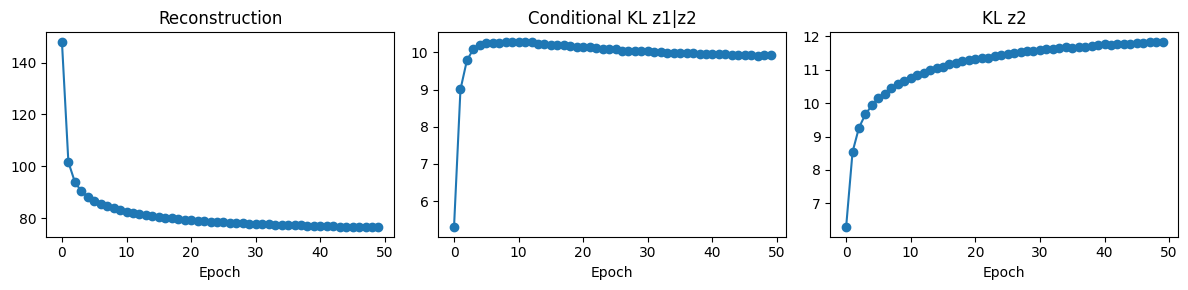

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, index, title in zip(axes, [1, 2, 3], ['Reconstruction', 'Conditional KL z1|z2', 'KL z2']):
    ax.plot([row[index] for row in history], marker='o')
    ax.set(title=title, xlabel='Epoch')
plt.tight_layout(); plt.show()

## Reconstruct and generate top-down

For generation, there is no encoder. First sample `z2` from its standard normal prior, use it to parameterize `p(z1|z2)`, sample `z1`, then decode both latents. This follows the model's dependency structure.

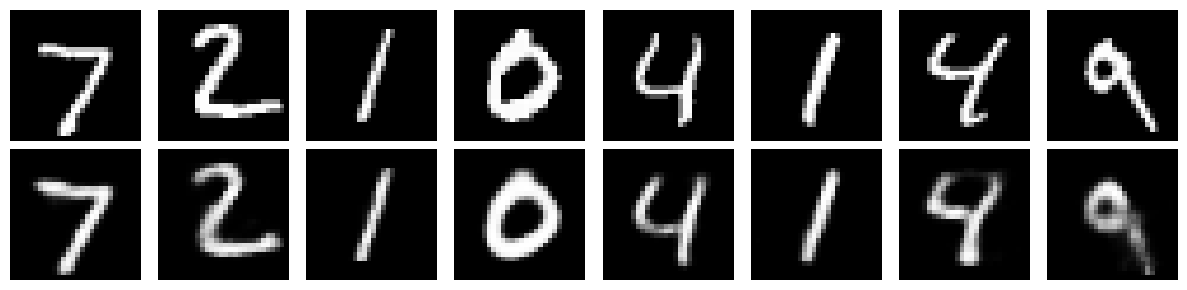

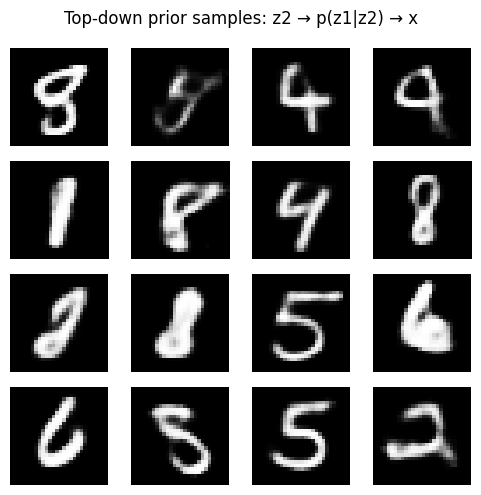

In [6]:
images, _ = next(iter(test_loader))
images = images[:8].to(device)
model.eval()
with torch.no_grad(): reconstruction, _ = model(images)
fig, axes = plt.subplots(2, 8, figsize=(12, 3))
for i in range(8):
    axes[0, i].imshow(images[i, 0].cpu(), cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(reconstruction[i, 0].cpu(), cmap='gray'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('Input'); axes[1, 0].set_ylabel('Reconstruction')
plt.tight_layout(); plt.show()

def sample_prior(model, count):
    z2 = torch.randn(count, model.dim_z2, device=device)
    mu1, logvar1 = model.conditional_prior(z2)
    z1 = model.sample(mu1, logvar1)
    return model.decode(z1, z2)

with torch.no_grad(): samples = sample_prior(model, 16).cpu()
fig, axes = plt.subplots(4, 4, figsize=(5, 5))
for ax, image in zip(axes.flat, samples):
    ax.imshow(image[0], cmap='gray'); ax.axis('off')
plt.suptitle('Top-down prior samples: z2 → p(z1|z2) → x')
plt.tight_layout(); plt.show()

## Takeaways and knowledge check

This model has a dependent joint prior `p(z2)p(z1|z2)`, unlike the independent prior model in notebook 05. Its inference path estimates `z2` from `x`, then estimates `z1` from both `x` and `z2`; generation samples in the reverse, top-down order. The conditional prior adds flexibility but also makes inference and optimization more involved.

A Ladder VAE adds a top-down pathway that combines higher-level context with bottom-up evidence to refine posterior inference; merely stacking latent vectors does not make a Ladder VAE. Hierarchical latents and multi-scale neural features are also distinct ideas, though they can be combined.

Monitor reconstruction and each KL contribution, latent statistics, sample diversity, validation behavior, and stability. Posterior collapse or level imbalance can occur; more latent levels do not guarantee meaningful abstractions. Use this added complexity when the data and task justify it.